Sentiment Breakdown:
Sentiment
Neutral     13
Positive     5
Negative     2
Name: count, dtype: int64


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


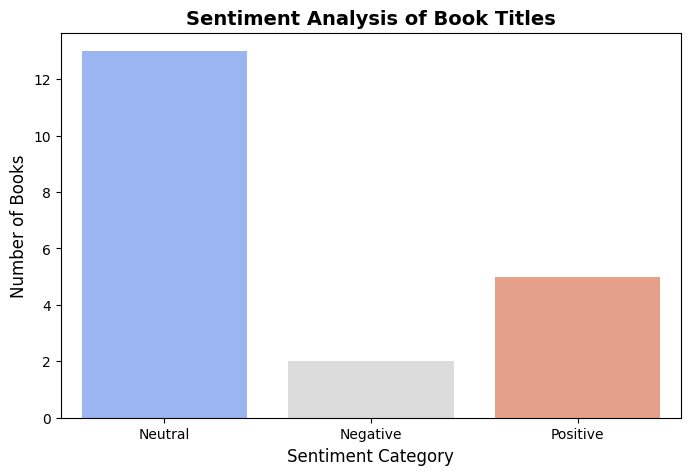

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Download VADER lexicon
nltk.download('vader_lexicon')

# Load dataset
df = pd.read_csv("codealpha_scraped_books.csv")

# Initialize VADER sentiment analyzer
sia = SentimentIntensityAnalyzer()

# Function to get sentiment label
def get_sentiment(text):
    score = sia.polarity_scores(str(text))['compound']
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

# Apply sentiment analysis on book titles using the correct column name
df['Sentiment'] = df['Book Title'].apply(get_sentiment)

# Output sentiment count breakdown
print("Sentiment Breakdown:")
print(df['Sentiment'].value_counts())

# Visualize Sentiment Distribution (updated for Seaborn)
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Sentiment', hue='Sentiment', palette='coolwarm', legend=False)
plt.title('Sentiment Analysis of Book Titles', fontsize=14, fontweight='bold')
plt.xlabel('Sentiment Category', fontsize=12)
plt.ylabel('Number of Books', fontsize=12)
plt.show()

In [2]:
print(df.columns)

Index(['Book Title', 'Price'], dtype='object')
